# Page: `_RPGM_Script` as a doc, `_RPGM_Event` as the actuator

**Short answer: yes, your idea is the better version of what I was recommending, and I would go with it.** Last time I said the script node should stay a child and only its command lists should be exports. Reading the code again, the script node owns nothing in the scene tree, so it can be a doc all the way.

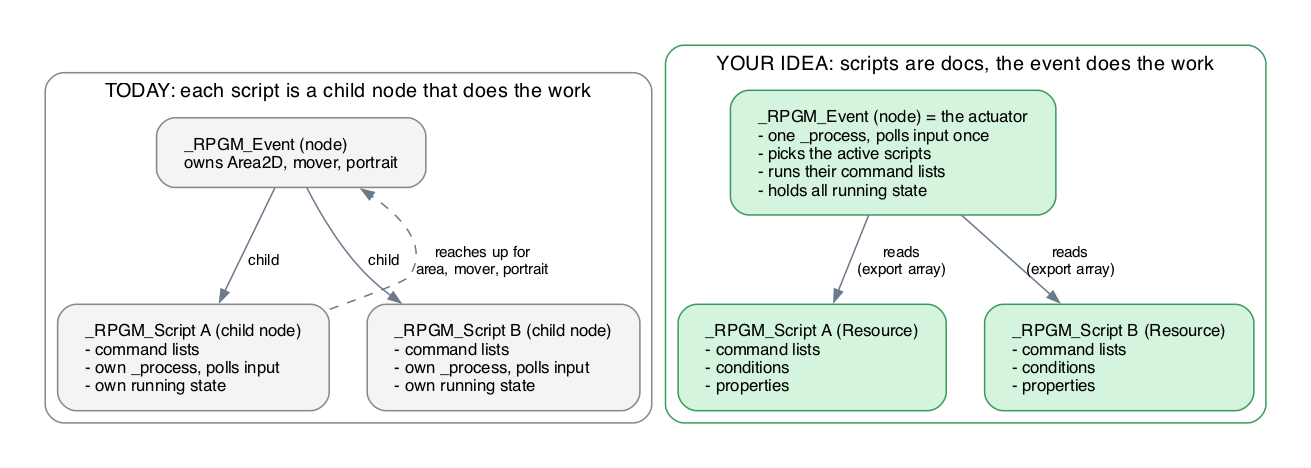

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB; compound=true; nodesep=0.35; ranksep=0.5;
  fontname="Helvetica"; fontsize=13;
  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", color="#888888", fontname="Helvetica", fontsize=11];
  edge [fontname="Helvetica", fontsize=10];

  subgraph cluster_today {
    label="TODAY: each script is a child node that does the work"; color="#888888"; style="rounded";
    t_event  [label="_RPGM_Event (node)\lowns Area2D, mover, portrait\l"];
    t_a [label="_RPGM_Script A (child node)\l- command lists\l- own _process, polls input\l- own running state\l"];
    t_b [label="_RPGM_Script B (child node)\l- command lists\l- own _process, polls input\l- own running state\l"];
    t_event -> t_a [label="child"];
    t_event -> t_b [label="child"];
    t_a -> t_event [label="reaches up for\narea, mover, portrait", style=dashed, constraint=false];
  }

  subgraph cluster_new {
    label="YOUR IDEA: scripts are docs, the event does the work"; color="#3c9a5f"; style="rounded";
    n_event [label="_RPGM_Event (node) = the actuator\l- one _process, polls input once\l- picks the active scripts\l- runs their command lists\l- holds all running state\l", fillcolor="#d4f4dd", color="#3c9a5f"];
    n_a [label="_RPGM_Script A (Resource)\l- command lists\l- conditions\l- properties\l", fillcolor="#d4f4dd", color="#3c9a5f"];
    n_b [label="_RPGM_Script B (Resource)\l- command lists\l- conditions\l- properties\l", fillcolor="#d4f4dd", color="#3c9a5f"];
    n_event -> n_a [label="reads\n(export array)"];
    n_event -> n_b [label="reads\n(export array)"];
  }
}
```

</details>

Where each piece of today's `_RPGM_Script` node would live:

| Piece of `_RPGM_Script` today | Goes to | Why / what I found in the code |
|---|---|---|
| `on_action`, `on_frame`, `on_area_entered`, `on_within_area` | **doc** (unchanged) | already `Array[_RPGM_Lambda]`, already data |
| `state_condition`, `variable_condition` | **doc**, read by the actuator | declared today but nothing reads them; active is decided by `_is_active()` overrides |
| `interrupt_player`, `is_collision`, `inplace_animation` | **doc** | plain settings |
| `_process` polling `ui_accept` and checking facing | **actuator** | same check for every script, so it runs once per event, not once per script |
| `body_entered` hookup, viewport-start hookup | **actuator** | the `Area2D` is the event's already (`get_parent().find_child("Area2D")`) |
| `trigger_is_running`, `is_running()` | **actuator**, one entry per script | a Resource can be shared between events, so it must not hold runtime state |
| `_update_active_state`, `_activate`, `_deactivate` | **actuator** | `_RPGM_Event` already has `all_scripts`, `active_scripts`, `update_active_scripts()` |
| `mover`, `portrait`, `get_event()`, `get_area()` | **deleted** | they only existed to reach the parent; the event passes itself: `lambda.run(rpgm_event)` |
| Subclasses: talker, teleport, ghost | **doc**, as command lists | talker needs a new face-player lambda; teleport's two lambdas exist; ghost's patrol loop needs a new lambda |
| **Result** | **doc = what to do, event = doing it** | **many scripts per event = an ordered array on the event, like RPG Maker event pages** |

Sketch of the shape (not tested, guard against re-entry left out):

```gdscript
# _rpgm_script.gd: the doc. No _process, no state.
extends Resource
class_name _RPGM_Script
@export var on_action : Array[_RPGM_Lambda]
@export_enum("A", "B", "C") var state_condition := "A"
@export var interrupt_player := false

# _rpgm_event.gd: the actuator.
@export var rpgm_scripts : Array[_RPGM_Script]
func _process(_delta):
	if not _player_pressed_action_on_this_event(): return
	for rpgm_script in _active_rpgm_scripts():
		await get_core().run_lambda_queue(self, rpgm_script.on_action)
```

- **Is children "un-Godot"? No.** Children are right when the child owns something in the tree. This one does not: its area, mover and portrait all belong to the parent. That is the sign it is data.
- **Actuator = functions inside `_RPGM_Event`, not a new node or class.** The event is already half of one. Split it out only if it grows.
- **Costs I found:**
  - The plugin (inspector plugin, bottom dock, lambda queue editor) edits a selected `_RPGM_Script` *node*. It would edit an entry of the event's array instead. Biggest piece of work, and you lose the scene-tree row per script.
  - Lambda `NodePath`s resolve from the node that runs them. That moves from the script to the event, so saved paths shift up one level.
  - Teleport exports `Node2D` fields. A Resource saved in a scene cannot hold a node, only a `NodePath` (how `_RPGM_Lambda_Transport_Player` already does it).
  - `run_lambda_queue` pops and re-appends the array it is given, and ghost rotates its `movement` array. Both edit the doc at runtime, which breaks once a doc is shared.
  - `_RPGM_Player._process` and `_RPGM_Viewport.can_save()` ask each script `is_running()`; they would ask the event.
- **Size of the move:** about 45 script nodes in scenes. 23 of them have their script written inside the scene (13 plain, 7 talker, 3 ghost); the rest use the shared teleport (13), talker (6) and plain (3) scripts. 3 events already have two scripts.
- **Order I would do it in, one small step each:**
  1. Move trigger detection from the script's `_process` into the event. Scripts stay nodes. The actuator now exists.
  2. Replace talker, teleport, ghost with command lists. No subclasses left.
  3. Flip `_RPGM_Script` to a Resource and add `rpgm_scripts` on the event. Move the 22 nodes, update the plugin.

  Steps 1 and 2 are worth having even if you stop before 3.

From reading the code only: nothing was changed or run. Background on the three composition styles: `composition-exports-children-editable-v2.ipynb`.
